In [ ]:
!pip install pandas openpyxl
!pip install matplotlib
!pip install seaborn
!pip install ipywidgets

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go

In [3]:
csv_i = pd.read_csv("modified_combined_normalized.csv")#alums
# Function to remove '\n' from column names
def remove_newline_chars(col_name):
    return col_name.replace('\n', '')

# Rename the columns
csv_i.rename(columns=remove_newline_chars, inplace=True)
csv_i = csv_i[(csv_i['YEAR'] >= 2015) & (csv_i['YEAR'] < 2022) & (csv_i['LEVEL'] == 'UG')]
csv_i

,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,HOME_STATE,ACTCOMP,SATOLDVERBAL,SATOLDMATH,SATNEWCOMP,PROGRAM,YEAR
0,M82268632,Cole Abel,cabel@mtu.edu,M,White/Non-Hispanic,UG,FR,EEE,NaN,Beaver Dam,WI,23.0,NaN,NaN,NaN,SYP,2018
1,M04509406,Andrew Ackerman,aackerma@mtu.edu,M,White/Non-Hispanic,UG,SO,ECM,NaN,Portage,IN,26.0,NaN,NaN,620.0,SYP,2018
2,M50494030,Bridget Alaniva,bialaniv@mtu.edu,F,White/Non-Hispanic,UG,SR,SCCM,HUME,Plymouth,MI,26.0,NaN,NaN,NaN,SYP,2018
3,M79846060,Laura Albrant,lealbran@mtu.edu,F,White/Non-Hispanic,UG,FR,SCS,NaN,Chassell,MI,NaN,NaN,NaN,610.0,SYP,2018
4,M79846060,Laura Albrant,lealbran@mtu.edu,F,White/Non-Hispanic,UG,FR,SCS,NaN,Chassell,MI,NaN,NaN,NaN,610.0,WCS,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11082,M16263360,Nick Zayan,nzayan@mtu.edu,M,White/Non-Hispanic,UG,SO,EEE,NaN,Fenton,MI,26.0,NaN,NaN,NaN,ESP,2016
11083,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,SYP,2016
11084,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,WCS,2016
11085,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,WIE,2016


In [4]:
csv_ii = pd.read_csv('modified_combined_normalized_attendees.csv')#attendees
def remove_newline_chars(col_name):
    return col_name.replace('\n', '')
# Rename the columns
csv_ii.rename(columns=remove_newline_chars, inplace=True)
csv_ii = csv_ii[(csv_ii['YEAR'] >= 2015) & (csv_ii['YEAR'] < 2022)]
csv_ii

,ID,PREFNAME_FL,ROOM,GENDER,AGE,CRN,COURSETITLE,TERMCODE,PTRM,YEAR,CONTINUITY
0,M00040356,Tee Johnson,0206W,M,21,51417,Engineering Scholars Program,201905,P05,2019,0
2,M00191357,Charles Byrnes,0551E,M,19,51385,Engineering Scholars Program,202105,P05,2021,0
3,M00218475,Ben Hale,0205W,M,21,51417,Engineering Scholars Program,201905,P05,2019,0
4,M00355028,Owen Gray,0204W,M,20,51417,Engineering Scholars Program,201905,P05,2019,0
5,M00355701,Kate Dempsey,0449W,F,19,52413,Michigan Species of Concern,202105,P01,2021,0
...,...,...,...,...,...,...,...,...,...,...,...
8618,M99950517,Trinity Metcalf,0452W,F,23,51420,Chemical Engineering,201705,P03,2017,0
8619,M99975346,JUNHO KIM,0511E,M,23,51425,Mechanical Eng: Automotive Eng,201705,P03,2017,0
8620,M99975823,Eddie Andrews,0249W,M,22,51916,PAAMEE,201805,P04,2018,0
8621,M99980102,Leah Corey,0401W,F,18,51192,Engineering 101,202105,P02,2021,0


In [5]:
department_mapping = {
    'EEE': 'Electrical Engineering',
    'ECM': 'Electrical Engineering',
    'SCCM': 'Electrical Engineering',
    'SCS': 'Electrical Engineering',
    'SPH': 'Electrical Engineering',
    'BGN': 'Electrical Engineering',
    'EMSE': 'Electrical Engineering',
    'ECP': 'Electrical Engineering',
    'STA': 'Electrical Engineering',
    'EBE': 'Electrical Engineering',
    'SAP': 'Health and Medical Sciences',
    'SBL': 'Business and Management',
    'EME': 'Mechanical Engineering',
    'EGE': 'Engineering and Applied Sciences',
    'EEN': 'Electrical Engineering',
    'FES': 'Environmental and Earth Sciences',
    'SCH': 'Education and Training',
    'EGL': 'Engineering and Applied Sciences',
    'BMGT': 'Business and Management',
    'SMA': 'Business and Management',
    'BEM': 'Business and Management',
    'SSEN': 'Social Sciences and Humanities',
    'SST': 'Social Sciences and Humanities',
    'SGSA': 'Social Sciences and Humanities',
    'SASE': 'Social Sciences and Humanities',
    'ECE': 'Electrical Engineering',
    'BMBA': 'Business and Management',
    'SPSY': 'Social Sciences and Humanities',
    'EAG': 'Environmental and Earth Sciences',
    'TCSA': 'Computer Science and IT',
    'TMET': 'Mechanical Engineering',
    'BMIS': 'Computer Science and IT',
    'SMBB': 'Science and Management',
    'SML': 'Science and Management',
    'STC': 'Business and Management',
    'SBI': 'Business and Management',
    'SESC': 'Engineering and Applied Sciences',
    'FGIS': 'Environmental and Earth Sciences',
    'FWEM': 'Environmental and Earth Sciences',
    'SFET': 'Mechanical Engineering',
    'EGN': 'Environmental and Earth Sciences',
    'BACC': 'Business and Management',
    'BMKT': 'Business and Management',
    'FFR': 'Finance',
    'TEET': 'Electrical Engineering',
    'TSE': 'Engineering and Applied Sciences',
    'EBS': 'Business and Management',
    'SSS': 'Social Sciences and Humanities',
    'BFIN': 'Finance',
    'SSFM': 'Finance',
    'SCHP': 'Education and Training',
    'SEN': 'Education and Training',
    'SANT': 'Education and Training',
    'TCMG': 'Computer Science and IT',
    'SFSD': 'Environmental and Earth Sciences',
    'FNRM': 'Environmental and Earth Sciences',
    'NDG': 'Engineering and Applied Sciences',
    'FMF': 'Health and Medical Sciences',
    'SEEP': 'Environmental and Earth Sciences',
    'SEMP': 'Environmental and Earth Sciences',
    'SSH': 'Social Sciences and Humanities',
    'SPA': 'Social Sciences and Humanities',
    'SFAT': 'Science and Management',
    'SSSU': 'Science and Management',
    'EGP': 'Environmental and Earth Sciences',
    'CCY': 'Computer Science and IT',
    'SCSC': 'Computer Science and IT',
    'SMBC': 'Business and Management',
    'BEC': 'Business and Management',
    'ERE': 'Environmental and Earth Sciences',
    'FWEC': 'Environmental and Earth Sciences',
    'IMX': 'Computer Science and IT',
    'IDS': 'Computer Science and IT',
    'SHB': 'Health and Medical Sciences',
    'SACS': 'Social Sciences and Humanities',
    'FAE': 'Fine Arts',
    'EMG': 'Engineering and Applied Sciences',
    'EECE': 'Electrical Engineering',
    'BMEM': 'Business and Management',
    'SKIN': 'Social Sciences and Humanities',
    'ECGE': 'Engineering and Applied Sciences',
    'SMCS': 'Science and Management',
    'CHI': 'Social Sciences and Humanities',
    'CWRM': 'Environmental and Earth Sciences',
    'CGN': 'Engineering and Applied Sciences',
    'EPD2': 'Engineering and Applied Sciences',
    'CNHD': 'Computer Science and IT',
    'SEEB': 'Social Sciences and Humanities',
    'PDS': 'Social Sciences and Humanities',
    'SAH': 'Social Sciences and Humanities',
    'EENS': 'Engineering and Applied Sciences',
    'IME': 'Engineering and Applied Sciences',
    'SRTC': 'Computer Science and IT',
    'SHF': 'Health and Medical Sciences',
    'SCMC': 'Engineering and Applied Sciences',
    'SCA': 'Education and Training',
    'SCB': 'Education and Training',
    'SKIP': 'Science and Management',
    'SPCD': 'Social Sciences and Humanities',
    'EEM': 'Engineering and Applied Sciences',
    'FESS': 'Environmental and Earth Sciences',
    'BOSM': 'Business and Management',
    'SCL': 'Education and Training',
    'SYP': 'Social Sciences and Humanities',
    'BBA': 'Business and Management',
    'SSM': 'Social Sciences and Humanities',
    'SYA': 'Social Sciences and Humanities',
    'SCSY': 'Social Sciences and Humanities',
    'TINT': 'Computer Science and IT',
    'STEC': 'Engineering and Applied Sciences',
    'EGR3': 'Engineering and Applied Sciences',
    'SSSH': 'Social Sciences and Humanities',
    'FFEM': 'Finance',
    'SFTT': 'Finance',
    'SCCS': 'Computer Science and IT',
    'SHU': 'Health and Medical Sciences',
    'TGN': 'Engineering and Applied Sciences',
    'SCHI': 'Education and Training',
    'IASC': 'Social Sciences and Humanities',
    'TGT': 'Education and Training'
}

# Map the department names to the DataFrame
csv_i['DEPARTMENT'] = csv_i['MAJORCODE'].map(department_mapping)
csv_i


,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,HOME_STATE,ACTCOMP,SATOLDVERBAL,SATOLDMATH,SATNEWCOMP,PROGRAM,YEAR,DEPARTMENT
0,M82268632,Cole Abel,cabel@mtu.edu,M,White/Non-Hispanic,UG,FR,EEE,NaN,Beaver Dam,WI,23.0,NaN,NaN,NaN,SYP,2018,Electrical Engineering
1,M04509406,Andrew Ackerman,aackerma@mtu.edu,M,White/Non-Hispanic,UG,SO,ECM,NaN,Portage,IN,26.0,NaN,NaN,620.0,SYP,2018,Electrical Engineering
2,M50494030,Bridget Alaniva,bialaniv@mtu.edu,F,White/Non-Hispanic,UG,SR,SCCM,HUME,Plymouth,MI,26.0,NaN,NaN,NaN,SYP,2018,Electrical Engineering
3,M79846060,Laura Albrant,lealbran@mtu.edu,F,White/Non-Hispanic,UG,FR,SCS,NaN,Chassell,MI,NaN,NaN,NaN,610.0,SYP,2018,Electrical Engineering
4,M79846060,Laura Albrant,lealbran@mtu.edu,F,White/Non-Hispanic,UG,FR,SCS,NaN,Chassell,MI,NaN,NaN,NaN,610.0,WCS,2018,Electrical Engineering
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11082,M16263360,Nick Zayan,nzayan@mtu.edu,M,White/Non-Hispanic,UG,SO,EEE,NaN,Fenton,MI,26.0,NaN,NaN,NaN,ESP,2016,Electrical Engineering
11083,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,SYP,2016,Social Sciences and Humanities
11084,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,WCS,2016,Social Sciences and Humanities
11085,M74701135,Elizabeth Zeck,erzeck@mtu.edu,F,White/Non-Hispanic,UG,FR,SSEN,NaN,Fostoria,MI,28.0,NaN,NaN,NaN,WIE,2016,Social Sciences and Humanities


In [35]:
csv_i['DEPARTMENT'].unique()

array(['Electrical Engineering', 'Health and Medical Sciences',
       'Business and Management', 'Mechanical Engineering',
       'Engineering and Applied Sciences',
       'Environmental and Earth Sciences', 'Education and Training',
       'Social Sciences and Humanities', 'Computer Science and IT',
       'Science and Management', 'Finance'], dtype=object)

In [6]:
# Define the mapping dictionary
course_mapping = {
    'other': [
        'PAAMEE',
        'Michigan Species of Concern',
        'Keweenaw Outdoor Adventure 101',
        'Mountaineering',
        'UNITE Biological Sciences',
        'UNITE ECE Exploration',
        'NEXT Scholars: Geospat Eng',
        'SYP Internship'
    ],
    'GU': [
        'Aquatic Ecology/Gratiot Lake', 'Aquatic Ecology', 'Wolf/Moose Backpack/Isle Royale',
        'Outdoor Skills and Leadership', 'Outdoor Leadership', 'Wolf and Wildlife Ecology',
        'Outdoor Adventures 101', 'Ship/Shore Freshwater Ecology', 'Honors Orchestra Program'
    ],
    'YGW': [
        'Be Your Own Boss', 'The Future of Manufacturing', 'The Gaming Industry Wants You!',
        'Calling All Writers', 'Design the Future', 'Medical Physiology',
        'Intro to Computational Physics', 'Medical Laboratory Science', 'Psychology in the Real World'
    ],
    'WIE': [
        'Women in Engineering (WIE)', 'Women in Automotive Eng',
        'Junior Women in Engineering'
    ],
    'YMT': [
        'Mechanical Eng: Automotive Eng', 'The Future of Manufacturing', 'Computer & Electrical Eng',
        'Mechanical Engineering', 'Aviation and Aerospace'
    ],
    'YPP': [],
    'FRS': [
        'Forensic Science and CSI', 'Stop the Hackers!'
    ],
    'ESP': [
        'Chemical Engineering', 'Electrical & Computer Eng', 'Mechanical Engineering',
        'Civil Engineering', 'Materials Science/Engineering', 'Geological Engineering'
    ],
    'YPO': [
        'Video Game Programming', 'Intro Video Game Programming', 'Coding for Internet of Things',
        'App & Web Dev: Design/Humans', 'Digital Photography', 'Computer Graphics and Design',
        'World of Design', 'Robotics 101'
    ],
    'WCS': [
        'Women in Computer Science', 'Women in Robotics', 'AI & Machine Learning'
    ],
    'YSG': [
        'Aquatic Ecology', 'Aquatic Ecology/Gratiot Lake', 'Wolf/Moose Backpack/Isle Royale',
        'Geological Engineering', 'Geohazards and Resource Eng', 'Environmental Invaders'
    ],
    'NST': [
        "NSTI: Nat'l Summer Trans Inst'", 'Rail/Intermodal Transportation'
    ],
    'NAS': [
        'Biotechnology', 'Genetic Modification & Biotech', 'Introduction to Microbiology',
        'Outdoor Leadership'
    ],
    'YPE': [
        'Mechanical Engineering', 'Electrical & Computer Eng', 'Engineering 101',
        'Rocketry and Space Science', 'Engineering Scholars Program'
    ]
}

# Function to map course titles to their respective program codes
def map_course_to_program(course_title):
    for program_code, courses in course_mapping.items():
        if course_title in courses:
            return program_code
    return None  # Return None if no matching program is found

# Apply the mapping to the 'COURSETITLE' column
csv_ii['Program_Code'] = csv_ii['COURSETITLE'].apply(map_course_to_program)

# Filter out rows where no program code was found (optional)
csv_ii = csv_ii.dropna(subset=['Program_Code'])
csv_ii


,ID,PREFNAME_FL,ROOM,GENDER,AGE,CRN,COURSETITLE,TERMCODE,PTRM,YEAR,CONTINUITY,Program_Code
0,M00040356,Tee Johnson,0206W,M,21,51417,Engineering Scholars Program,201905,P05,2019,0,YPE
2,M00191357,Charles Byrnes,0551E,M,19,51385,Engineering Scholars Program,202105,P05,2021,0,YPE
3,M00218475,Ben Hale,0205W,M,21,51417,Engineering Scholars Program,201905,P05,2019,0,YPE
4,M00355028,Owen Gray,0204W,M,20,51417,Engineering Scholars Program,201905,P05,2019,0,YPE
5,M00355701,Kate Dempsey,0449W,F,19,52413,Michigan Species of Concern,202105,P01,2021,0,other
...,...,...,...,...,...,...,...,...,...,...,...,...
8618,M99950517,Trinity Metcalf,0452W,F,23,51420,Chemical Engineering,201705,P03,2017,0,ESP
8619,M99975346,JUNHO KIM,0511E,M,23,51425,Mechanical Eng: Automotive Eng,201705,P03,2017,0,YMT
8620,M99975823,Eddie Andrews,0249W,M,22,51916,PAAMEE,201805,P04,2018,0,other
8621,M99980102,Leah Corey,0401W,F,18,51192,Engineering 101,202105,P02,2021,0,YPE


In [7]:
csv_ii['Program_Code'].unique()

array(['YPE', 'other', 'ESP', 'GU', 'NAS', 'WIE', 'NST', 'YMT', 'FRS',
       'YGW', 'YPO', 'WCS', 'YSG'], dtype=object)

In [8]:
csv_i['DEPARTMENT'].unique()

array(['Electrical Engineering', 'Health and Medical Sciences',
       'Business and Management', 'Mechanical Engineering',
       'Engineering and Applied Sciences',
       'Environmental and Earth Sciences', 'Education and Training',
       'Social Sciences and Humanities', 'Computer Science and IT',
       'Science and Management', 'Finance'], dtype=object)

# ----------------------x-------------x-----------------

In [9]:
#Filters for alums only
csv_i.loc[:, 'Transition_Path'] = csv_i.groupby('ID')['MAJORCODE'].transform(
    lambda x: 'Changed' if len(x.unique()) > 1 else 'Same'
)
csv_i.loc[:, 'Broad_Path'] = csv_i.apply(
    lambda x: f"{x['YEAR']} - {x['CLASS']}", axis=1
)

In [10]:
# Step 1: Calculate the first and last year of enrollment for each student
csv_i['First_Year'] = csv_i.groupby('ID')['YEAR'].transform('min')
csv_i['Last_Year'] = csv_i.groupby('ID')['YEAR'].transform('max')

# Step 2: Calculate the number of years enrolled (duration)
csv_i['Year_Duration'] = csv_i['Last_Year'] - csv_i['First_Year'] + 1

# Step 3: Categorize students based on the number of years enrolled
def categorize_duration(year_duration):
    if year_duration <= 2:
        return '1st-2nd Year'
    elif year_duration <= 4:
        return '3rd-4th Year'
    else:
        return '5th+ Year'

csv_i['Year_Category'] = csv_i['Year_Duration'].apply(categorize_duration)

# Step 4: Create a simplified path based on the Year_Category, PROGRAM, and CLASS
csv_i['Simplified_Path'] = csv_i.apply(
    lambda x: f"{x['Year_Category']} - {x['PROGRAM']} - {x['CLASS']}", axis=1
)

# Now you can continue with your Sankey diagram or any other analysis using 'Simplified_Path'


In [11]:
csv_i.loc[:, 'Simplified_Path'] = csv_i.apply(
    lambda x: f"{x['YEAR']} - {x['PROGRAM'].split()[0]} - {x['CLASS']}", axis=1
)

In [12]:
# Sort by ID to ensure all occurrences of the same ID are together
csv_i_sorted = csv_i.sort_values(by='ID').reset_index(drop=True)


## GRADUATED STUDENTS
- Check if Broad_Path ends with "SR" – This indicates that the student was a senior in their last recorded year.
- Ensure Last_Year equals the maximum year for that student – This would signify their final year.
- Look at Simplified_Path for graduation indicators – This column may show a path that can help confirm graduation.


In [13]:
import pandas as pd

graduated_students = csv_i_sorted[
    (csv_i_sorted['Broad_Path'].str.endswith('SR')) &  # Senior year
    (csv_i_sorted['Last_Year'] == csv_i_sorted['YEAR']) &  # Final year matches last year in dataset
    (csv_i_sorted['Simplified_Path'].str.endswith('SR'))  # Check the simplified path for confirmation
]


In [14]:
graduated_students = graduated_students.drop_duplicates(subset='ID')
graduated_students

,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,...,PROGRAM,YEAR,DEPARTMENT,Transition_Path,Broad_Path,First_Year,Last_Year,Year_Duration,Year_Category,Simplified_Path
1,M00080531,Matthew Switzer,mhswitze@mtu.edu,M,White/Non-Hispanic,UG,SR,ECE,NaN,Livonia,...,SYP,2021,Electrical Engineering,Same,2021 - SR,2019,2021,3,3rd-4th Year,2021 - SYP - SR
2,M00248544,Zach Hill,zwhill@mtu.edu,M,White/Non-Hispanic,UG,SR,BFIN,NaN,Hancock,...,SYP,2017,Finance,Same,2017 - SR,2015,2017,3,3rd-4th Year,2017 - SYP - SR
7,M00249024,Ian Provoast,ikprovoa@mtu.edu,M,White/Non-Hispanic,UG,SR,SSH,NaN,Houghton,...,SYP,2018,Social Sciences and Humanities,Changed,2018 - SR,2016,2018,3,3rd-4th Year,2018 - SYP - SR
8,M00249401,Cody Yazzie,cjyazzie@mtu.edu,M,Multiracial,UG,SR,ECM,NaN,Mount Pleasant,...,GU,2015,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - GU - SR
9,M00252020,Surbhi Thakur,sthakur@mtu.edu,F,Asian/Asian American,UG,SR,EEN,ECEM,Rockville,...,SYP,2015,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - SYP - SR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6415,M99399865,Brenden Blazier,brblazie@mtu.edu,M,White/Non-Hispanic,UG,SR,EME,NaN,Iron Mountain,...,SYP,2021,Mechanical Engineering,Same,2021 - SR,2018,2021,4,3rd-4th Year,2021 - SYP - SR
6419,M99403918,Ricky Greub,rjgreub@mtu.edu,M,White/Non-Hispanic,UG,SR,BACC,NaN,Dollar Bay,...,SYP,2020,Business and Management,Same,2020 - SR,2017,2020,4,3rd-4th Year,2020 - SYP - SR
6424,M99559917,Theresa Weber,tweber@mtu.edu,F,White/Non-Hispanic,UG,SR,SFET,NaN,Gulliver,...,WIE,2019,Mechanical Engineering,Changed,2019 - SR,2015,2019,5,5th+ Year,2019 - WIE - SR
6434,M99638326,Ross Samuelson,rlsamuel@mtu.edu,M,White/Non-Hispanic,UG,SR,TMET,EMSM,Phelps,...,SYP,2020,Mechanical Engineering,Same,2020 - SR,2015,2020,6,5th+ Year,2020 - SYP - SR


## LEFT STUDENTS

In [15]:
import pandas as pd

last_class_per_student = csv_i_sorted.groupby('ID')['CLASS'].max()

left_before_senior = last_class_per_student[~last_class_per_student.isin(['SR', 'PO', 'PS', 'SG'])]

left_students = csv_i_sorted[csv_i_sorted['ID'].isin(left_before_senior.index)]

left_students = left_students[~left_students['Simplified_Path'].str.contains('SR', case=False, na=False)]

In [16]:
last_class_per_student

ID
M00080531    SR
M00248544    SR
M00249024    SR
M00249401    SR
M00252020    SR
             ..
M99559917    SR
M99631147    SO
M99638326    SR
M99694376    SR
M99792374    JR
Name: CLASS, Length: 1680, dtype: object

In [17]:
left_students = left_students.groupby('ID').first().reset_index()
left_students

,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,...,PROGRAM,YEAR,DEPARTMENT,Transition_Path,Broad_Path,First_Year,Last_Year,Year_Duration,Year_Category,Simplified_Path
0,M00348748,Ian Figures,itfigure@mtu.edu,M,Hispanic/Hispanic American,UG,JR,BMKT,None,Hancock,...,SYP,2018,Business and Management,Same,2018 - JR,2018,2018,1,1st-2nd Year,2018 - SYP - JR
1,M00387929,Leah Pennala,lgpennal@mtu.edu,F,White/Non-Hispanic,UG,FR,BGN,None,Houghton,...,YGW,2018,Electrical Engineering,Same,2018 - FR,2018,2019,2,1st-2nd Year,2018 - YGW - FR
2,M00484336,Brianna Adkins,bmadkins@mtu.edu,F,Hispanic/Hispanic American,UG,FR,TEET,None,Detroit,...,SYP,2021,Electrical Engineering,Same,2021 - FR,2021,2021,1,1st-2nd Year,2021 - SYP - FR
3,M00706842,Evan Wazny,edwazny@mtu.edu,M,White/Non-Hispanic,UG,FR,EME,None,Midland,...,SYP,2020,Mechanical Engineering,Same,2020 - FR,2020,2020,1,1st-2nd Year,2020 - SYP - FR
4,M00740392,Seth Stajdl,scstajdl@mtu.edu,M,White/Non-Hispanic,UG,JR,SCS,None,Saginaw,...,SYP,2021,Electrical Engineering,Same,2021 - JR,2019,2021,3,3rd-4th Year,2021 - SYP - JR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
658,M99076760,Logan Powell,lapowell@mtu.edu,M,Not Supplied,UG,FR,TCSA,None,Saginaw,...,YMT,2017,Computer Science and IT,Same,2017 - FR,2017,2017,1,1st-2nd Year,2017 - YMT - FR
659,M99210186,Riley Nelson,rwnelson@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Appleton,...,SYP,2020,Mechanical Engineering,Changed,2020 - FR,2019,2021,3,3rd-4th Year,2020 - SYP - FR
660,M99333745,Caleb Sanders,cfsander@mtu.edu,M,White/Non-Hispanic,UG,FR,EME,None,Houghton,...,SYP,2020,Mechanical Engineering,Same,2020 - FR,2020,2021,2,1st-2nd Year,2020 - SYP - FR
661,M99631147,Kaden Arsenault,kmarsena@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Grant,...,SYP,2019,Mechanical Engineering,Same,2019 - FR,2019,2021,3,3rd-4th Year,2019 - SYP - FR


# ----------------------x-------------x-----------------

- "csv_i_sorted" must be taken as an output dataframe for alums.

In [18]:
#Applying filters
# Sort by ID and YEAR to get the latest entry for each student
#Taking the sorted output of special filter
csv_i_f1 = csv_i_sorted.sort_values(['ID', 'YEAR'], ascending=[True, True])
csv_ii_f2 = csv_ii.sort_values(['ID', 'YEAR'], ascending=[True, True])

In [19]:
# Group by ID and get the last entry for each student (this will be their final major)
csv_i_f1 = csv_i_f1.groupby('ID').last().reset_index()
csv_ii_f2= csv_ii_f2.groupby('ID').last().reset_index()

In [20]:
print(csv_i_f1.shape)
print(csv_ii_f2.shape)

(1680, 25)
(4809, 12)


In [21]:
# Assuming you already have your dataframes (csv_i_f1 and csv_ii_f2)
import pandas as pd

# Save csv_i_f1 to a CSV file
csv_i_f1.to_csv('csv_i_f1.csv', index=False)

# Save csv_ii_f2 to a CSV file
csv_ii_f2.to_csv('csv_ii_f2.csv', index=False)




In [22]:
duplicate_ids = csv_i_f1['ID'].duplicated().any()
print(duplicate_ids)
duplicate_ids = csv_ii_f2['ID'].duplicated().any()
print(duplicate_ids)

False
False


In [65]:
print(csv_i_f1.columns)
print(csv_ii_f2.columns)

Index(['ID', 'NAMEPREFLAST', 'EMAIL_ADDRESS', 'GENDER', 'STVETHN_DESC',
       'LEVEL', 'CLASS', 'MAJORCODE', 'MINORCODE', 'HOME_CITY', 'HOME_STATE',
       'ACTCOMP', 'SATOLDVERBAL', 'SATOLDMATH', 'SATNEWCOMP', 'PROGRAM',
       'YEAR', 'DEPARTMENT', 'Transition_Path', 'Broad_Path', 'First_Year',
       'Last_Year', 'Year_Duration', 'Year_Category', 'Simplified_Path'],
      dtype='object')
Index(['ID', 'PREFNAME_FL', 'ROOM', 'GENDER', 'AGE', 'CRN', 'COURSETITLE',
       'TERMCODE', 'PTRM', 'YEAR', 'CONTINUITY', 'Program_Code', 'Retained'],
      dtype='object')


In [63]:
# Check which attendees are retained in the university
csv_ii_f2['Retained'] = csv_ii_f2['ID'].isin(csv_i_f1['ID'])

# Calculate retention statistics
total_attendees = csv_ii_f2.shape[0]
total_retained = csv_ii_f2['Retained'].sum()

# Calculate retention rate
retention_rate = (total_retained / total_attendees) * 100 if total_attendees > 0 else 0

print(f'Total Attendees: {total_attendees}')
print(f'Total Retained: {total_retained}')
print(f'Retention Rate: {retention_rate:.2f}%')


Total Attendees: 4809
Total Retained: 709
Retention Rate: 14.74%


In [28]:
# Check how many students were retained directly
retained_counts = csv_ii_f2['ID'].isin(csv_i_f1['ID']).value_counts()

# Calculate the number of retained and total attendees
total_attendees = csv_ii_f2.shape[0]
total_retained = retained_counts[True] if True in retained_counts else 0

# Calculate retention rate
retention_rate = (total_retained / total_attendees) * 100 if total_attendees > 0 else 0

print(f'Total Attendees: {total_attendees}')
print(f'Total Retained: {total_retained}')
print(f'Retention Rate: {retention_rate:.2f}%')


Total Attendees: 4809
Total Retained: 709
Retention Rate: 14.74%


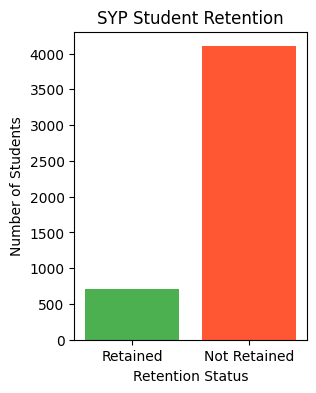

In [64]:
import matplotlib.pyplot as plt

# Visualization
labels = ['Retained', 'Not Retained']
sizes = [total_retained, total_attendees - total_retained]
colors = ['#4CAF50', '#FF5733']  # Green for retained, red for not retained

plt.figure(figsize=(3, 4))
plt.bar(labels, sizes, color=colors)
plt.title('SYP Student Retention')
plt.xlabel('Retention Status')
plt.ylabel('Number of Students')
plt.show()


### Program-wise retention

In [29]:
# Group by 'COURSETITLE' and calculate the retention rate for each course
course_retention = csv_ii_f2.groupby('COURSETITLE')['ID'].apply(lambda x: x.isin(csv_i_f1['ID']).mean() * 100)

print(course_retention)


COURSETITLE
AI & Machine Learning              0.000000
App & Web Dev: Design/Humans      15.384615
Aquatic Ecology                    2.631579
Aquatic Ecology/Gratiot Lake      28.571429
Aviation and Aerospace             3.488372
Be Your Own Boss                  15.000000
Biotechnology                      2.857143
Calling All Writers                5.882353
Chemical Engineering              23.456790
Civil Engineering                 11.111111
Coding for Internet of Things      9.677419
Computer & Electrical Eng         18.840580
Computer Graphics and Design       0.000000
Design the Future                 18.750000
Digital Photography                3.225806
Electrical & Computer Eng          2.173913
Engineering 101                   17.307692
Engineering Scholars Program      22.278481
Environmental Invaders            20.000000
Forensic Science and CSI           5.529954
Genetic Modification & Biotech    20.454545
Geohazards and Resource Eng        0.000000
Geological Engineeri

In [36]:
# Step 1: Merge the dataframes on 'ID'
merged_df = pd.merge(csv_ii_f2, csv_i_f1[['ID']], on='ID', how='left', indicator=True)

# Step 2: Create a flag indicating whether the student was retained
merged_df['Retained'] = merged_df['_merge'] == 'both'  # Retained if the student exists in both dataframes

# Step 3: Group by 'COURSETITLE' and calculate the retention rate
course_retention_alt = merged_df.groupby('COURSETITLE')['Retained'].mean() * 100

# Step 4: Display the retention rates
print(course_retention_alt)


COURSETITLE
AI & Machine Learning              0.000000
App & Web Dev: Design/Humans      15.384615
Aquatic Ecology                    2.631579
Aquatic Ecology/Gratiot Lake      28.571429
Aviation and Aerospace             3.488372
Be Your Own Boss                  15.000000
Biotechnology                      2.857143
Calling All Writers                5.882353
Chemical Engineering              23.456790
Civil Engineering                 11.111111
Coding for Internet of Things      9.677419
Computer & Electrical Eng         18.840580
Computer Graphics and Design       0.000000
Design the Future                 18.750000
Digital Photography                3.225806
Electrical & Computer Eng          2.173913
Engineering 101                   17.307692
Engineering Scholars Program      22.278481
Environmental Invaders            20.000000
Forensic Science and CSI           5.529954
Genetic Modification & Biotech    20.454545
Geohazards and Resource Eng        0.000000
Geological Engineeri

### Department-wise retention

In [30]:
# Group by 'COURSETITLE' and calculate the retention rate for each course
course_retention = csv_i_f1.groupby('DEPARTMENT')['ID'].apply(lambda x: x.isin(csv_ii_f2['ID']).mean() * 100)

print(course_retention)

DEPARTMENT
Business and Management             26.811594
Computer Science and IT             41.509434
Education and Training              30.434783
Electrical Engineering              46.833773
Engineering and Applied Sciences    31.081081
Environmental and Earth Sciences    53.225806
Finance                             11.764706
Health and Medical Sciences         60.000000
Mechanical Engineering              42.335766
Science and Management              36.734694
Social Sciences and Humanities      44.117647
Name: ID, dtype: float64


In [31]:
# Merge the dataframes to see which students from csv_ii_f2 are also in csv_i_f1 (retained students)
merged_df_left = pd.merge(csv_i_f1[['ID', 'DEPARTMENT']], csv_ii_f2[['ID']], on='ID', how='left', indicator=True)

# Create a 'Retained' column to identify whether the student is retained or not
merged_df_left['Retained'] = merged_df_left['_merge'] == 'both'

# Calculate the retention percentage department-wise
retention_by_department = merged_df_left.groupby('DEPARTMENT')['Retained'].mean() * 100

print(retention_by_department)

DEPARTMENT
Business and Management             26.811594
Computer Science and IT             41.509434
Education and Training              30.434783
Electrical Engineering              46.833773
Engineering and Applied Sciences    31.081081
Environmental and Earth Sciences    53.225806
Finance                             11.764706
Health and Medical Sciences         60.000000
Mechanical Engineering              42.335766
Science and Management              36.734694
Social Sciences and Humanities      44.117647
Name: Retained, dtype: float64


# ------------X------------X-----------------X---------------X

In [56]:
# Merge the dataframes to retain all columns from csv_i_f1 and match on 'ID'
merged_df_viz = pd.merge(csv_i_f1, csv_ii_f2[['ID']], on='ID', how='left', indicator=True)
merged_df_viz = merged_df_viz.drop(merged_df_viz.columns[-1], axis=1)
# Check for duplicates based on a specific column, e.g., 'ID'
duplicates_in_column = merged_df_viz[merged_df_viz.duplicated(subset=['ID'])]

# Print the duplicates in the 'ID' column
print(duplicates_in_column)

Empty DataFrame
Columns: [ID, NAMEPREFLAST, EMAIL_ADDRESS, GENDER, STVETHN_DESC, LEVEL, CLASS, MAJORCODE, MINORCODE, HOME_CITY, HOME_STATE, ACTCOMP, SATOLDVERBAL, SATOLDMATH, SATNEWCOMP, PROGRAM, YEAR, DEPARTMENT, Transition_Path, Broad_Path, First_Year, Last_Year, Year_Duration, Year_Category, Simplified_Path]
Index: []

[0 rows x 25 columns]


In [57]:
#1
print(merged_df_viz.columns)
print(merged_df_viz.shape)
#2
print(graduated_students.columns)
print(graduated_students.shape)
#3
print(left_students.columns)
print(left_students.shape)

Index(['ID', 'NAMEPREFLAST', 'EMAIL_ADDRESS', 'GENDER', 'STVETHN_DESC',
       'LEVEL', 'CLASS', 'MAJORCODE', 'MINORCODE', 'HOME_CITY', 'HOME_STATE',
       'ACTCOMP', 'SATOLDVERBAL', 'SATOLDMATH', 'SATNEWCOMP', 'PROGRAM',
       'YEAR', 'DEPARTMENT', 'Transition_Path', 'Broad_Path', 'First_Year',
       'Last_Year', 'Year_Duration', 'Year_Category', 'Simplified_Path'],
      dtype='object')
(1680, 25)
Index(['ID', 'NAMEPREFLAST', 'EMAIL_ADDRESS', 'GENDER', 'STVETHN_DESC',
       'LEVEL', 'CLASS', 'MAJORCODE', 'MINORCODE', 'HOME_CITY', 'HOME_STATE',
       'ACTCOMP', 'SATOLDVERBAL', 'SATOLDMATH', 'SATNEWCOMP', 'PROGRAM',
       'YEAR', 'DEPARTMENT', 'Transition_Path', 'Broad_Path', 'First_Year',
       'Last_Year', 'Year_Duration', 'Year_Category', 'Simplified_Path'],
      dtype='object')
(1010, 25)
Index(['ID', 'NAMEPREFLAST', 'EMAIL_ADDRESS', 'GENDER', 'STVETHN_DESC',
       'LEVEL', 'CLASS', 'MAJORCODE', 'MINORCODE', 'HOME_CITY', 'HOME_STATE',
       'ACTCOMP', 'SATOLDVERBAL', 'SAT

In [59]:
# Add a new column to identify graduated and left students
graduated_students['Status'] = 'Graduated'
left_students['Status'] = 'Left'

# Merge the dataframes, combining rows and keeping the new 'Status' column
merged_df_gl = pd.concat([graduated_students, left_students], ignore_index=True)

# Now you can differentiate students based on the 'Status' column
merged_df_gl

,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,...,YEAR,DEPARTMENT,Transition_Path,Broad_Path,First_Year,Last_Year,Year_Duration,Year_Category,Simplified_Path,Status
0,M00080531,Matthew Switzer,mhswitze@mtu.edu,M,White/Non-Hispanic,UG,SR,ECE,NaN,Livonia,...,2021,Electrical Engineering,Same,2021 - SR,2019,2021,3,3rd-4th Year,2021 - SYP - SR,Graduated
1,M00248544,Zach Hill,zwhill@mtu.edu,M,White/Non-Hispanic,UG,SR,BFIN,NaN,Hancock,...,2017,Finance,Same,2017 - SR,2015,2017,3,3rd-4th Year,2017 - SYP - SR,Graduated
2,M00249024,Ian Provoast,ikprovoa@mtu.edu,M,White/Non-Hispanic,UG,SR,SSH,NaN,Houghton,...,2018,Social Sciences and Humanities,Changed,2018 - SR,2016,2018,3,3rd-4th Year,2018 - SYP - SR,Graduated
3,M00249401,Cody Yazzie,cjyazzie@mtu.edu,M,Multiracial,UG,SR,ECM,NaN,Mount Pleasant,...,2015,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - GU - SR,Graduated
4,M00252020,Surbhi Thakur,sthakur@mtu.edu,F,Asian/Asian American,UG,SR,EEN,ECEM,Rockville,...,2015,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - SYP - SR,Graduated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1668,M99076760,Logan Powell,lapowell@mtu.edu,M,Not Supplied,UG,FR,TCSA,None,Saginaw,...,2017,Computer Science and IT,Same,2017 - FR,2017,2017,1,1st-2nd Year,2017 - YMT - FR,Left
1669,M99210186,Riley Nelson,rwnelson@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Appleton,...,2020,Mechanical Engineering,Changed,2020 - FR,2019,2021,3,3rd-4th Year,2020 - SYP - FR,Left
1670,M99333745,Caleb Sanders,cfsander@mtu.edu,M,White/Non-Hispanic,UG,FR,EME,None,Houghton,...,2020,Mechanical Engineering,Same,2020 - FR,2020,2021,2,1st-2nd Year,2020 - SYP - FR,Left
1671,M99631147,Kaden Arsenault,kmarsena@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Grant,...,2019,Mechanical Engineering,Same,2019 - FR,2019,2021,3,3rd-4th Year,2019 - SYP - FR,Left


In [ ]:
#Checking 7 extra stdents who are neither
# Find IDs in merged_df_viz but not in merged_df_gl
students_in_viz_not_gl = merged_df_viz[~merged_df_viz['ID'].isin(merged_df_gl['ID'])]

# Output the result
students_in_viz_not_gl


,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,...,PROGRAM,YEAR,DEPARTMENT,Transition_Path,Broad_Path,First_Year,Last_Year,Year_Duration,Year_Category,Simplified_Path
388,M25305340,Hayley Long,hllong@mtu.edu,F,White/Non-Hispanic,UG,SG,SAH,None,Mishawaka,...,SYP,2015,Social Sciences and Humanities,Same,2015 - SG,2015,2015,1,1st-2nd Year,2015 - SYP - SG
616,M39396447,Nicole Yarroch,npyarroc@mtu.edu,F,White/Non-Hispanic,UG,PO,SCS,None,Hancock,...,SYP,2015,Electrical Engineering,Same,2015 - PO,2015,2015,1,1st-2nd Year,2015 - SYP - PO
669,M42422959,Taylor Michels,tjmichel@mtu.edu,M,White/Non-Hispanic,UG,PO,ECP,None,Baraga,...,SYP,2019,Electrical Engineering,Same,2019 - PO,2018,2019,2,1st-2nd Year,2019 - SYP - PO
901,M55896139,Sam Perram,sdperram@mtu.edu,M,White/Non-Hispanic,UG,PO,EME,None,Laurium,...,SYP,2015,Mechanical Engineering,Same,2015 - PO,2015,2015,1,1st-2nd Year,2015 - SYP - PO
914,M56417497,Jacob Coulson,jacoulso@mtu.edu,M,White/Non-Hispanic,UG,PO,SCS,MSEM,Kentwood,...,SYP,2021,Electrical Engineering,Changed,2021 - PO,2015,2021,7,5th+ Year,2021 - SYP - PO
918,M56675719,Matt Radke,mpradke@mtu.edu,M,White/Non-Hispanic,UG,PO,STA,None,Houghton,...,SYP,2016,Electrical Engineering,Changed,2016 - PO,2015,2016,2,1st-2nd Year,2016 - SYP - PO
1645,M98216308,Ryan Piotrowski,rhpiotro@mtu.edu,M,Not Supplied,UG,PO,SMA,None,Neenah,...,ESP,2020,Business and Management,Changed,2020 - PO,2015,2020,6,5th+ Year,2020 - ESP - PO


In [ ]:
#Creating a Retained column
merged_df_gl['Retained'] = csv_ii_f2['ID'].isin(csv_i_f1['ID'])
# Replace True with 'Retained' and False with 'Not Retained' in the 'Retained' column
merged_df_gl['Retained'] = merged_df_gl['Retained'].replace({True: 'Retained', False: 'Not Retained'})
# Create a new column in merged_df_gl to indicate matching course titles
merged_df_gl['COURSETITLES'] = merged_df_gl['ID'].map(csv_ii_f2.set_index('ID')['COURSETITLE'])

# View the changes
merged_df_gl

,ID,NAMEPREFLAST,EMAIL_ADDRESS,GENDER,STVETHN_DESC,LEVEL,CLASS,MAJORCODE,MINORCODE,HOME_CITY,...,DEPARTMENT,Transition_Path,Broad_Path,First_Year,Last_Year,Year_Duration,Year_Category,Simplified_Path,Status,Retained
0,M00080531,Matthew Switzer,mhswitze@mtu.edu,M,White/Non-Hispanic,UG,SR,ECE,NaN,Livonia,...,Electrical Engineering,Same,2021 - SR,2019,2021,3,3rd-4th Year,2021 - SYP - SR,Graduated,Not Retained
1,M00248544,Zach Hill,zwhill@mtu.edu,M,White/Non-Hispanic,UG,SR,BFIN,NaN,Hancock,...,Finance,Same,2017 - SR,2015,2017,3,3rd-4th Year,2017 - SYP - SR,Graduated,Not Retained
2,M00249024,Ian Provoast,ikprovoa@mtu.edu,M,White/Non-Hispanic,UG,SR,SSH,NaN,Houghton,...,Social Sciences and Humanities,Changed,2018 - SR,2016,2018,3,3rd-4th Year,2018 - SYP - SR,Graduated,Not Retained
3,M00249401,Cody Yazzie,cjyazzie@mtu.edu,M,Multiracial,UG,SR,ECM,NaN,Mount Pleasant,...,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - GU - SR,Graduated,Not Retained
4,M00252020,Surbhi Thakur,sthakur@mtu.edu,F,Asian/Asian American,UG,SR,EEN,ECEM,Rockville,...,Electrical Engineering,Same,2015 - SR,2015,2015,1,1st-2nd Year,2015 - SYP - SR,Graduated,Not Retained
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1668,M99076760,Logan Powell,lapowell@mtu.edu,M,Not Supplied,UG,FR,TCSA,None,Saginaw,...,Computer Science and IT,Same,2017 - FR,2017,2017,1,1st-2nd Year,2017 - YMT - FR,Left,Retained
1669,M99210186,Riley Nelson,rwnelson@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Appleton,...,Mechanical Engineering,Changed,2020 - FR,2019,2021,3,3rd-4th Year,2020 - SYP - FR,Left,Not Retained
1670,M99333745,Caleb Sanders,cfsander@mtu.edu,M,White/Non-Hispanic,UG,FR,EME,None,Houghton,...,Mechanical Engineering,Same,2020 - FR,2020,2021,2,1st-2nd Year,2020 - SYP - FR,Left,Not Retained
1671,M99631147,Kaden Arsenault,kmarsena@mtu.edu,M,White/Non-Hispanic,UG,FR,TMET,None,Grant,...,Mechanical Engineering,Same,2019 - FR,2019,2021,3,3rd-4th Year,2019 - SYP - FR,Left,Not Retained


In [ ]:
merged_df_gl['COURSETITLES']

# Some_useful_visuals

In [73]:
# Assuming the data is already loaded in csv_norm_2015_2023_ug
# Node 1: Group by 'LEVEL' and 'DEPARTMENT'
san_year_level = merged_df_gl.groupby(['Status', 'Retained'])['ID'].count().reset_index()
san_year_level = san_year_level.rename(columns={'Status': 'source', 'Retained': 'target', 'ID': 'value'})

# Node 2: Group by 'DEPARTMENT' and 'PROGRAM'
san_year_program = merged_df_gl.groupby(['Retained', 'DEPARTMENT'])['ID'].count().reset_index()
san_year_program = san_year_program.rename(columns={'Retained': 'source', 'DEPARTMENT': 'target', 'ID': 'value'})

# Combine the two datasets
combined_df = pd.concat([san_year_level, san_year_program])

# Unique values that contain unique values of source and target
unique_nodes = list(pd.unique(combined_df[['source', 'target']].values.ravel("K")))

# Dictionary to map nodes to indices
mapping_dict = {k: v for v, k in enumerate(unique_nodes)}

# Map the nodes in the DataFrame
combined_df['source'] = combined_df['source'].map(mapping_dict)
combined_df['target'] = combined_df['target'].map(mapping_dict)

# Convert DataFrame to a dictionary with lists
link_dict = combined_df.to_dict(orient="list")

# Step 1: Calculate counts for each node
node_counts = combined_df.groupby('source')['value'].sum().to_dict()
node_counts.update(combined_df.groupby('target')['value'].sum().to_dict())

# Step 2: Create a new label with counts
updated_labels = [f"{node} ({node_counts.get(idx, 0)})" for idx, node in enumerate(unique_nodes)]

# Step 3: Create the Sankey diagram with updated labels
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=updated_labels,  # Use updated labels here
    ),
    link=dict(
        source=link_dict["source"],
        target=link_dict["target"],
        value=link_dict["value"],
    )
)])

# Update layout
fig.update_layout(title_text="Sankey Diagram for students in general", font_size=10)

# Display the Sankey diagram
fig.show()


In [ ]:
# Assuming the data is already loaded in csv_norm_2015_2023_ug
# Node 1: Group by 'LEVEL' and 'DEPARTMENT'
san_year_level = merged_df_gl.groupby(['Status', 'Retained'])['ID'].count().reset_index()
san_year_level = san_year_level.rename(columns={'Status': 'source', 'Retained': 'target', 'ID': 'value'})

# Node 2: Group by 'DEPARTMENT' and 'PROGRAM'
san_year_program = merged_df_gl.groupby(['Retained', 'DEPARTMENT'])['ID'].count().reset_index()
san_year_program = san_year_program.rename(columns={'Retained': 'source', 'DEPARTMENT': 'target', 'ID': 'value'})

# Combine the two datasets
combined_df = pd.concat([san_year_level, san_year_program])

# Unique values that contain unique values of source and target
unique_nodes = list(pd.unique(combined_df[['source', 'target']].values.ravel("K")))

# Dictionary to map nodes to indices
mapping_dict = {k: v for v, k in enumerate(unique_nodes)}

# Map the nodes in the DataFrame
combined_df['source'] = combined_df['source'].map(mapping_dict)
combined_df['target'] = combined_df['target'].map(mapping_dict)

# Convert DataFrame to a dictionary with lists
link_dict = combined_df.to_dict(orient="list")

# Step 1: Calculate counts for each node
node_counts = combined_df.groupby('source')['value'].sum().to_dict()
node_counts.update(combined_df.groupby('target')['value'].sum().to_dict())

# Step 2: Create a new label with counts
updated_labels = [f"{node} ({node_counts.get(idx, 0)})" for idx, node in enumerate(unique_nodes)]

# Step 3: Create the Sankey diagram with updated labels
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=updated_labels,  # Use updated labels here
    ),
    link=dict(
        source=link_dict["source"],
        target=link_dict["target"],
        value=link_dict["value"],
    )
)])

# Update layout
fig.update_layout(title_text="Sankey Diagram for students in general", font_size=10)

# Display the Sankey diagram
fig.show()


In [ ]:
import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

# Sample data (Assuming your data already exists in combined_df)
# Modify combined_df, source, target, and other info as needed in your case.

# Step 1: Function to update the Sankey diagram based on a widget's selection
def update_sankey_diagram(filter_option):
    # Filter the combined_df based on widget selection (filter_option)
    if filter_option == "All":
        filtered_df = merged_df_gl
    else:
        filtered_df = merged_df_gl[merged_df_gl['source'] == mapping_dict[filter_option]]
    
    # Recreate the Sankey diagram based on the filtered data
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=updated_labels,  # Your updated labels here
        ),
        link=dict(
            source=filtered_df["source"],
            target=filtered_df["target"],
            value=filtered_df["value"],
        )
    )])

    # Update layout
    fig.update_layout(title_text=f"Sankey Diagram Filtered by: {filter_option}", font_size=10)

    # Display the Sankey diagram
    fig.show()

# Step 2: Create a widget (Dropdown) to filter the Sankey diagram
filter_dropdown = widgets.Dropdown(
    options=["All"] + unique_nodes,  # Options based on your nodes + 'All' to show everything
    description='Filter:',
    disabled=False,
)

# Step 3: Interactive display
widgets.interactive(update_sankey_diagram, filter_option=filter_dropdown)

# Step 4: Display the widget
display(filter_dropdown)

# Note: Your 'combined_df', 'mapping_dict', and 'updated_labels' should already be defined 
# based on the logic for the Sankey diagram generation you provided earlier.


Dropdown(description='Status:', options=('Graduated', 'Left'), value='Graduated')